# 07. Вакансии 2026 года из Telegram: разбор и объединение с данными 2024

**Источник:** Telegram-канал «Jobs | Работа и Вакансии из ИТ сферы» (@codifynews), посты с 01.01.2026,
собраны через официальный Telegram API (`kg-salary-prediction/src/collect_telegram.py`).
Телефоны и @username в текстах заменены на `[телефон]` и `[контакт]` при сборе.

**Цель:** привести посты к той же таблице, что и данные 2024 (`vacancies_clean.csv`),
с точной датой публикации, и сохранить объединённый файл `vacancies_2024_2026.csv`.

Большинство постов построено по шаблону:
```
Название вакансии
Компания: ...
ЗП: От 30000 до 70000 KGS в месяц
Тип: Полная занятость | office | remote ...
Дополнительно: От 1 до 3 лет, Бишкек
```

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline, make_union
from sklearn.svm import LinearSVC

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
pd.set_option("display.max_colwidth", 90)

raw = pd.read_json("../data/raw/telegram_posts.jsonl", lines=True)
raw["published"] = pd.to_datetime(raw["date"], utc=True).dt.tz_convert(None)   # UTC, как в данных 2024
log = []
def note(step, why, rows): log.append({"шаг": step, "почему": why, "строк": int(rows)})
print(f"Постов: {len(raw)} | каналы: {raw['channel'].unique().tolist()}")
print(f"Период: {raw['published'].min()} – {raw['published'].max()}")

Постов: 15213 | каналы: ['1093436171', 'codifynews']
Период: 2026-01-01 03:01:01 – 2026-10-28 10:00:27


## 1. Даты

Дата берётся из метки времени Telegram (`date`, UTC, с точностью до секунды) и хранится в том же
виде, что и в данных 2024: колонка `published` (UTC без часового пояса). Дополнительно
добавлены `year` и `pub_month`.

**Ограничение:** это дата публикации **в канале**. Канал перепубликует вакансии с сайтов, поэтому
реальная дата размещения вакансии может быть на несколько дней раньше.

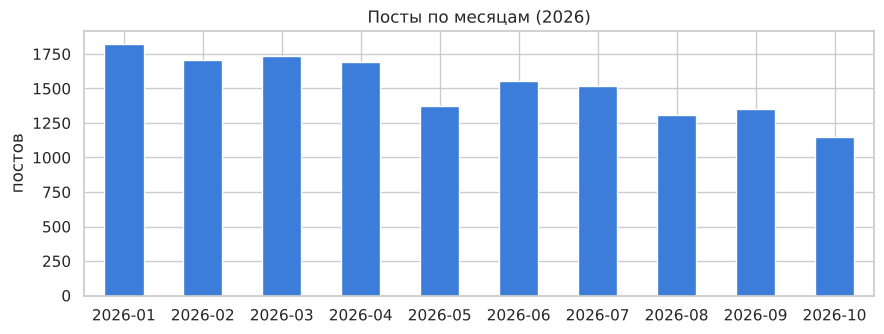

In [2]:
m = raw["published"].dt.to_period("M").value_counts().sort_index()
ax = m.plot(kind="bar", figsize=(9, 3.5), color="#3b7dd8")
ax.set_title("Посты по месяцам (2026)"); ax.set_xlabel(""); ax.set_ylabel("постов")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIG + "07_tg_months.png", dpi=150); plt.show()

## 2. Только вакансии по шаблону

In [3]:
is_tpl = raw["text"].str.contains("Компания:") & raw["text"].str.contains("ЗП:")
note("Удалены посты не по шаблону", "реклама, анонсы, новости каналов; 20 постов DevKG в другом формате", (~is_tpl).sum())
tg = raw[is_tpl].copy()
print(raw.loc[~is_tpl, "text"].str.slice(0, 80).to_string())

first_line = tg["text"].str.split("\n").str[0].str.strip()
field = lambda k: tg["text"].str.extract(rf"{k}:\s*(.*)")[0].str.strip()
tg["name"] = first_line
tg["company"] = field("Компания")
tg["zp"] = field("ЗП")
tg["type"] = field("Тип")
tg["extra"] = field("Дополнительно")
tg[["name", "company", "zp", "type", "extra"]].head(8)

0          Большое обновление DevKG\n\nИстория DevKG началась 24 ноября 2016 года с первого с
1          Небольшой бонус для тех, кто ищет сотрудников\n\nНа DevKG можно получить 2500 бону
2          Инженерно-техническая группа ГТС: QA Engineer\nТип: Работа в офисе\nОт 89000 KGS д
3          platadev: Python Backend Developer\nТип: Работа в офисе\nОт 100000 KGS до 150000 K
4         Reviro: 💼 IT Sales Manager\nТип: Работа в офисе\nОт 100000 KGS\nТэги: #reviro #offi
5          Kagan: Senior Backend-разработчик (NodeJS)\nТип: Работа в офисе\nОт 3000 USD в мес
6         Tuz Ventures: Аналитик\nТип: Офис или удалённо\nОт 120000 KGS до 180000 KGS\nТэги: 
7         Kagan: Technical Project Manager\nТип: Работа в офисе\nОт 120000 KGS в месяц\nТэги:
8           Torus: Менеджер по развитию бизнеса (B2B SaaS / AI / Automation)\nТип: Удалённая 
9          Флюра-ТЕХ: middle .NET разработчик\nТип: Работа в офисе\nОт 80000 KGS до 100000 KG
10        Middle Android Developer\nТип: Работа в офисе\nОт 

,name,company,zp,type,extra
20,Специалист по работе с клиентами,ОсДО Биринчи ломбард Кэй Джи,Не указана,Полная занятость,"Без опыта, Бишкек"
21,Специалист технической поддержки,MBank,От 40000 KGS в месяц,office,NaN
22,SMM-специалист (Social Media Marketing Specialist),ОсОО Нэксия КэйДжи,Не указана,Полная занятость,"От 1 до 3 лет, Бишкек"
23,Сениор-тестировщик/QA-инженер,MBank,От 100000 KGS в месяц,office,NaN
24,"Руководитель компании (операционный директор / управляющий офисом), Кыргызстан",ОсОО Джо энд Кэш Инвест,50000 - 100000 KGS,Полная занятость,"От 1 до 3 лет, Бишкек"
25,Senior Java Developer,MBank,От 170000 KGS в месяц,office,NaN
26,Менеджер по продажам,ОсОО Аманат Сити Групп,Не указана,Полная занятость,"От 1 до 3 лет, Бишкек"
27,Тимлид разработчик,MBank,От 250000 KGS в месяц,office,NaN


## 3. Дубликаты

Канал повторно публикует одну и ту же вакансию. Дубликат: одинаковые название, компания и зарплата.
Оставляется **первая** публикация: её дата ближе всего к дате появления вакансии.

In [4]:
norm = lambda s: s.fillna("").str.lower().str.replace(r"[^а-яёa-z0-9]+", " ", regex=True).str.strip()
tg["dup_key"] = norm(tg["name"]) + "|" + norm(tg["company"]) + "|" + norm(tg["zp"])
tg = tg.sort_values("published")
dup = tg.duplicated("dup_key", keep="first")
note("Удалены повторные публикации", "одинаковые название + компания + зарплата; оставлена первая", dup.sum())
tg = tg[~dup].copy()
print(f"Уникальных вакансий: {len(tg)}")

Уникальных вакансий: 8595


## 4. Зарплата

Форматы: «От 30000 до 70000 KGS в месяц», «50000 - 90000 KGS», «от 60000 KGS», «до 80000»,
«Не указана», «Договорная», «Неоплачиваемая».

- валюта не указана → сомы;
- **рубли и тенге → вакансия удаляется** (работодатели из России и Казахстана, другой рынок);
- USD и EUR → сомы по курсу НБКР на **30.06.2026** (середина периода): 87,45 и 99,68 сома;
- «в час» → × 8 часов × 26 дней, как в данных 2024;
- «Неоплачиваемая» → вакансия удаляется (стажировки без оплаты).

In [5]:
RATES = {"KGS": 1.0, "USD": 87.45, "EUR": 99.6843}
z = tg["zp"].fillna("")
cur = z.str.extract(r"(KGS|USD|EUR|RUB|RUR|KZT|₽|\$|€|₸|сом)", flags=re.I)[0].str.upper()
cur = cur.replace({"$": "USD", "€": "EUR", "₽": "RUB", "RUR": "RUB", "₸": "KZT", "СОМ": "KGS"})
nums = z.str.replace(r"(?<=\d)[\s\u00a0](?=\d{3})", "", regex=True).str.findall(r"\d+(?:[.,]\d+)?")
nums = nums.apply(lambda xs: [float(x.replace(",", ".")) for x in xs])

has_num = nums.str.len() > 0
cur = cur.where(~has_num | cur.notna(), "KGS")
lo_word = z.str.contains(r"^\s*от", case=False) & ~z.str.contains(r"\bдо\b", case=False)
hi_word = z.str.contains(r"^\s*до", case=False)
tg["compensation_from"] = np.where(hi_word, np.nan, nums.str[0])
tg["compensation_to"] = np.where(hi_word, nums.str[0], np.where(lo_word, np.nan, nums.str[1]))
tg.loc[~has_num, ["compensation_from", "compensation_to"]] = np.nan
tg["compensation_currency"] = np.where(has_num, cur, None)

foreign = tg["compensation_currency"].isin(["RUB", "KZT"])
unpaid = z.str.contains("Неоплачиваем", case=False)
note("Удалены вакансии в рублях и тенге", "работодатели из России и Казахстана", foreign.sum())
note("Удалены неоплачиваемые стажировки", "нет зарплаты как таковой", unpaid.sum())
tg = tg[~foreign & ~unpaid].copy()

f, t = tg["compensation_from"], tg["compensation_to"]
tg["salary_type"] = np.select([f.notna() & t.notna(), f.notna(), t.notna()], ["range", "from", "to"], default="hidden")
raw_sal = np.where(f.notna() & t.notna(), (f + t) / 2, f.fillna(t))
tg["salary_kgs"] = raw_sal * tg["compensation_currency"].map(RATES)
hourly = tg["zp"].str.contains("в час", na=False)
tg.loc[hourly, "salary_kgs"] *= 8 * 26
tg["pay_period"] = np.where(tg["salary_kgs"].notna(), np.where(hourly, "hour", "month"), None)
note("Почасовая ставка пересчитана в месяц", "× 8 часов × 26 дней", (hourly & tg["salary_kgs"].notna()).sum())
note("Пересчёт USD/EUR в сомы", "курс НБКР на 30.06.2026", tg["compensation_currency"].isin(["USD", "EUR"]).sum())

LOW, HIGH = 10_000, 600_000
out = tg["salary_kgs"].notna() & ((tg["salary_kgs"] < LOW) | (tg["salary_kgs"] > HIGH))
note("Зарплата < 10 тыс или > 600 тыс обнулена", "как в данных 2024; вакансия сохранена", out.sum())
tg["salary_outlier"] = out
tg.loc[out, "salary_kgs"] = np.nan
tg["salary_hidden"] = tg["salary_type"] == "hidden"
tg["has_salary"] = tg["salary_kgs"].notna()
tg["salary_type"].value_counts()

salary_type
range     3163
hidden    3008
from      2066
to           3
Name: count, dtype: int64

In [6]:
check = tg[tg["zp"].str.contains(r"\d", na=False)].sample(12, random_state=3)
check[["zp", "compensation_from", "compensation_to", "compensation_currency", "salary_kgs"]]

,zp,compensation_from,compensation_to,compensation_currency,salary_kgs
12643,от 60000 KGS,60000.0,NaN,KGS,60000.0
9799,500 - 2500 USD,500.0,2500.0,USD,131175.0
11283,40000 - 60000 KGS,40000.0,60000.0,KGS,50000.0
9634,от 40000 KGS,40000.0,NaN,KGS,40000.0
12208,45000 - 50000 KGS,45000.0,50000.0,KGS,47500.0
1946,от 25000 KGS,25000.0,NaN,KGS,25000.0
401,30000 - 70000 KGS,30000.0,70000.0,KGS,50000.0
8625,50000 - 80000 KGS,50000.0,80000.0,KGS,65000.0
1773,От 60000 KGS в месяц,60000.0,NaN,KGS,60000.0
2671,от 50000 KGS,50000.0,NaN,KGS,50000.0


## 5. Опыт, город, формат работы

- `Дополнительно: От 1 до 3 лет, Бишкек` → опыт и город (те же группы, что в 2024);
- в коротком шаблоне опыт задан уровнем: Стажёр/Младший → «нет опыта», Средний → «1–3 года»,
  Старший → «3–6 лет», Ведущий → «6+ лет»;
- если опыт не указан: группа «не указан», `experience_start` = 1 (самое частое значение) и
  флаг `experience_known = False`;
- город не указан → «не указан».

In [7]:
ex = tg["extra"].fillna("")
exp_map = {"Без опыта": 0, "От 1 до 3 лет": 1, "От 3 до 6 лет": 3, "Более 6 лет": 6}
lvl_map = {"Стажёр": 0, "Младший": 0, "Средний": 1, "Старший": 3, "Ведущий": 6}
exp_txt = ex.str.extract(r"^(Без опыта|От 1 до 3 лет|От 3 до 6 лет|Более 6 лет)")[0]
lvl_txt = tg["type"].fillna("").str.extract(r"(Стажёр|Младший|Средний|Старший|Ведущий)")[0]
start = exp_txt.map(exp_map).fillna(lvl_txt.map(lvl_map))
tg["experience_known"] = start.notna()
tg["experience_start"] = start.fillna(1).astype(int)
tg["experience"] = np.where(tg["experience_known"],
                            tg["experience_start"].map({0: "нет опыта", 1: "1–3 года", 3: "3–6 лет", 6: "6+ лет"}),
                            "не указан")

tg["area"] = ex.str.extract(r",\s*([^,]+)$")[0].str.strip().fillna("не указан")
tg["city"] = np.select([tg["area"] == "Бишкек", tg["area"] == "Ош", tg["area"] == "не указан"],
                       ["Бишкек", "Ош", "не указан"], default="Регионы")
typ = tg["type"].fillna("").str.lower()
tg["remote"] = typ.str.contains("remote|удал")
print(tg["experience"].value_counts(), "\n")
print(tg["city"].value_counts())

experience
1–3 года     4057
не указан    1740
3–6 лет      1398
нет опыта     850
6+ лет        195
Name: count, dtype: int64 

city
Бишкек       5669
не указан    2324
Ош            141
Регионы       106
Name: count, dtype: int64


## 6. Сфера и профессия

В постах нет `category` и `sub_category`. Их предсказывает классификатор, обученный на данных 2024
только по **названию вакансии** (TF-IDF по буквам и словам + линейный SVM), потому что в постах
нет текста требований. Точность на отложенных вакансиях 2024 выводится ниже. Колонка `category_predicted = True` отмечает,
что значения предсказаны.

In [8]:
v24 = pd.read_csv("../data/processed/vacancies_clean.csv", parse_dates=["published"], low_memory=False)
# В постах есть только название вакансии, поэтому классификатор обучается тоже только на названиях:
# иначе он учится на длинных текстах требований и ошибается на коротких постах.
def clf():
    return make_pipeline(make_union(
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
        TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)), LinearSVC(C=0.5))
title24 = v24["name"].fillna("").str.lower()
tg["requirements"] = ""            # в постах нет текста требований: только название и компания
tg["responsibilities"] = ""
title_tg = tg["name"].fillna("").str.lower()

# точность на отложенных вакансиях 2024 (только hh: по формату ближе всего к постам)
from sklearn.model_selection import GroupShuffleSplit
grp = title24.str.replace(r"[^а-яёa-z]+", " ", regex=True)
a, b = next(GroupShuffleSplit(1, test_size=0.2, random_state=0).split(v24, groups=grp))
hh_b = b[v24["source"].values[b] == "headhunter"]
for col in ["category", "sub_category"]:
    acc_all = (clf().fit(title24.iloc[a], v24[col].iloc[a]).predict(title24.iloc[b]) == v24[col].iloc[b]).mean()
    acc_hh = (clf().fit(title24.iloc[a], v24[col].iloc[a]).predict(title24.iloc[hh_b]) == v24[col].iloc[hh_b]).mean()
    print(f"{col}: точность на отложенных вакансиях 2024: все {acc_all:.0%}, hh {acc_hh:.0%}")
    tg[col] = clf().fit(title24, v24[col]).predict(title_tg)
tg["category_predicted"] = True
tg["category"].value_counts().head(12)

category: точность на отложенных вакансиях 2024: все 81%, hh 74%


sub_category: точность на отложенных вакансиях 2024: все 76%, hh 61%


category
Продажи, обслуживание клиентов       3062
Информационные технологии            1810
Маркетинг, реклама, PR               1259
Другое                                612
Строительство, недвижимость           414
Стратегия, инвестиции, консалтинг     320
Финансы, бухгалтерия                  259
Управление персоналом, тренинги        84
Туризм, гостиницы, рестораны           70
Административный персонал              68
Наука, образование                     56
Розничная торговля                     46
Name: count, dtype: int64

In [9]:
tg[["name", "company", "category", "sub_category"]].sample(15, random_state=5)

,name,company,category,sub_category
4907,IT Support Engineer,ОсОО Алга Интерактив,Информационные технологии,"Программист, разработчик"
11101,Менеджер по продажам,ОсОО Линк Инвест,"Продажи, обслуживание клиентов","Менеджер по продажам, менеджер по работе с клиентами"
4979,Руководитель отдела маркетинга,ОсОО Кеденов групп,"Маркетинг, реклама, PR",Директор по маркетингу и PR (CMO)
377,Помощник на поручения в it корпорацию,Алыпов Артём Романович,Административный персонал,"Секретарь, помощник руководителя, ассистент"
5348,"Инженер поддержки (Python Developer, Junior+)",MBANK,Информационные технологии,"Программист, разработчик"
12911,Ассистент проекта,ОФ Лингва,Административный персонал,"Секретарь, помощник руководителя, ассистент"
8342,DevOps Engineer,"ОАО ""Тундук""",Информационные технологии,DevOps-инженер
5299,"Технический специалист по обслуживанию оборудования (LED-экраны, медиаборды)",FOEL,Другое,Другое
2464,Интегратор Битрикс24,Земкин Д. О.,Информационные технологии,"Программист, разработчик"
6401,Менеджер по продажам спецтехники,ОсОО Техно Премьер,"Продажи, обслуживание клиентов","Менеджер по продажам, менеджер по работе с клиентами"


## 7. Остальные колонки как в 2024 и объединение

In [10]:
t = (tg["name"].fillna("") + " " + tg["type"].fillna("")).str.lower()
tg["education"] = "не указано"
tg["gender_req"] = np.select([t.str.contains(r"девушк|женщин"), t.str.contains(r"\bпарн|мужчин")],
                             ["женщины", "мужчины"], default="не указано")
tg["schedule"] = "не указан"
tg["commission"] = t.str.contains(r"процент|% от|бонус")
tg["kyrgyz_text"] = t.str.contains("[өүң]")
tg["skills"] = np.nan
tg["n_skills"] = 0
tg["text_len"] = 0
tg["id"] = "tg_" + tg["msg_id"].astype(str)
tg["source"] = "telegram"
tg["pub_month"] = tg["published"].dt.to_period("M").astype(str)

v24 = v24.assign(year=v24["published"].dt.year, category_predicted=False, experience_known=True)
tg["year"] = tg["published"].dt.year
cols = list(v24.columns)
combined = pd.concat([v24, tg[cols]], ignore_index=True)
combined["period"] = np.where(combined["source"] == "telegram", "2026 (Telegram)", "2024 (hh + lalafo)")
combined.to_csv("../data/processed/vacancies_2024_2026.csv", index=False)

log_df = pd.DataFrame(log)
log_df.loc[len(log_df)] = {"шаг": "Итого вакансий 2026", "почему": f"было {len(raw)} постов", "строк": len(tg)}
display(log_df)
summary = combined.groupby("period").agg(вакансий=("id", "size"), с_зарплатой=("has_salary", "sum"),
                                         скрыта=("salary_hidden", "mean"), медиана=("salary_kgs", "median"),
                                         с=("published", "min"), по=("published", "max"))
summary.style.format({"скрыта": "{:.0%}", "медиана": "{:,.0f}"})

,шаг,почему,строк
0,Удалены посты не по шаблону,"реклама, анонсы, новости каналов; 20 постов DevKG в другом формате",28
1,Удалены повторные публикации,одинаковые название + компания + зарплата; оставлена первая,6590
2,Удалены вакансии в рублях и тенге,работодатели из России и Казахстана,320
3,Удалены неоплачиваемые стажировки,нет зарплаты как таковой,35
4,Почасовая ставка пересчитана в месяц,× 8 часов × 26 дней,54
5,Пересчёт USD/EUR в сомы,курс НБКР на 30.06.2026,840
6,Зарплата < 10 тыс или > 600 тыс обнулена,как в данных 2024; вакансия сохранена,36
7,Итого вакансий 2026,было 15213 постов,8240


,вакансий,с_зарплатой,скрыта,медиана,с,по
period,,,,,,
2024 (hh + lalafo),12646,5840,52%,"39,000",2017-01-23 05:28:13,2024-03-30 13:38:31
2026 (Telegram),8240,5196,37%,"70,000",2026-01-01 03:01:01,2026-10-28 09:41:10


## Выводы и ограничения

**Что получилось:**
- Из 15 213 постов получено **8 240 уникальных вакансий 2026 года** (1 января – 28 октября),
  из них **5 196 с зарплатой** (63%). Повторные публикации составляли почти половину постов (6 590).
- **Даты точные:** у каждой вакансии метка времени Telegram первой публикации, от 615 до 1 257 вакансий
  в месяц, без пропусков.
- **Зарплата:** 4 373 в сомах, 791 в долларах, 32 в евро; 320 вакансий в рублях и тенге удалены
  как другой рынок.
- **Скрытых зарплат меньше, чем в 2024:** 37% против 52%.
- Таблица полностью совпадает по колонкам с данными 2024; объединённый файл:
  `data/processed/vacancies_2024_2026.csv` (20 886 вакансий; колонки `period`, `year`, `source`
  отличают годы и источники).

**Ограничения, которые важно учитывать при сравнении:**
1. **Состав рынка другой.** Канал публикует в основном офисные, IT и продажные вакансии, а данные 2024
   включают общепит, производство, сферу услуг. Поэтому общая медиана (70 000 против 39 000) **не
   сравнима**: сравнивать нужно одинаковые профессии и, лучше всего, с hh 2024 (самый похожий формат).
2. **Один канал-агрегатор.** Это не весь рынок 2026 года.
3. **Нет текста требований:** в посте только название, компания, зарплата, опыт и город.
4. **Сфера и профессия предсказаны** классификатором (точность на hh 2024: сфера 74%, профессия 61%).
5. **Опыт известен у ~80% вакансий, город у ~72%**; для остальных указано «не указан».
6. Дата это дата публикации в канале, она может быть на несколько дней позже размещения вакансии.

**Попутно найдено:** в справочнике источника 2024 профессия «Менеджер по продажам» была отнесена к сфере
«Спортивные клубы, фитнес, салоны красоты»; исправлено в `02_cleaning`.